In [33]:
import psycopg2

In [34]:
import os
print(os.getcwd())

c:\Users\morga\OneDrive - Duke University\Coding Projects\Adyn DIIG\DIIG-F26-Adyn\morgan


In [35]:
import os
from dotenv import load_dotenv

load_dotenv()

conn = psycopg2.connect(
    host=os.environ["DB_HOST"],
    port=os.environ["DB_PORT"],
    dbname=os.environ["DB_NAME"],
    user=os.environ["DB_USER"],
    password=os.environ["DB_PASSWORD"]
)

In [36]:
with conn.cursor() as cur:
    cur.execute("SELECT * FROM RxOrders LIMIT 10;")
    rows = cur.fetchall()

    for row in rows:
        print(row)

('225cfbd0-abd2-4781-a25b-5005a28a2092', 'ADRX1XZO0S4K', '9902067c-8ea2-46e7-9cd9-bcf9f72c2b61', 'cus_Lt4NfaGGdTncq7', 'processed', '5ef5834b-4b45-404e-85f4-a8727b6376d5', 'AD-BC-DAYSEE00', 2, 'Sig', 'ADYN', True, True, 0, None, 'price_1LGBy1ApFTaOcYxWBuNW1zcY', 'ii_1LeiCSApFTaOcYxW4etgDPKC', 'in_1LeiCsApFTaOcYxWIoCKfJ6N', datetime.datetime(2022, 9, 5, 16, 31, 4, 295483), datetime.datetime(2022, 9, 5, 16, 31, 30, 940148), datetime.datetime(2022, 9, 5, 16, 27, 40, 548207), datetime.datetime(2024, 1, 8, 20, 59, 59, 552053), None, True, True, None, None, False, None, True, None)
('03ea3b7d-0599-41ac-9a58-89071a1c5545', 'ADRXFXP5NRVS', '3bdea8bd-498e-4406-b26f-8a43886f0802', 'cus_PEKeIjw7gvoU1v', None, '47fb76f4-81cd-49d1-91b3-3348d73d3aba', 'AD-BC-FALMIN20', 1, '3', 'note', True, True, 5, None, 'price_1LHSwpApFTaOcYxW2Zu3uxBn', 'ii_1PBlceApFTaOcYxWDwNv8VWc', 'in_1PBld0ApFTaOcYxWTPkJZcG2', datetime.datetime(2024, 5, 1, 19, 10, 10, 516283), datetime.datetime(2024, 5, 1, 22, 27, 54, 904750),

In [37]:
#check column names of RxOrders
with conn.cursor() as cur:
    cur.execute("SELECT * FROM RxOrders LIMIT 0;")
    print([col[0] for col in cur.description])

['id', 'friendly_order_id', 'customer_id', 'stripe_customer_id', 'status', 'prescriber_id', 'sku', 'quantity', 'signetur', 'note_to_pharmacy', 'bc_prescribed', 'rx_submitted_to_adyn_pharmacy', 'refills_allowed', 'customer_cost', 'stripe_price_id', 'stripe_invoice_item_id', 'stripe_invoice_id', 'date_order_placed', 'date_order_paid', 'created_date', 'modified_date', 'days_supply', 'customer_approved', 'adyn_approved', 'customer_disapproved_reason', 'adyn_disapproved_reason', 'suspended', 'suspended_reason', 'customer_visibility', 'appointment_id']


In [38]:
#check column names of RxOrderHistory
with conn.cursor() as cur:
    cur.execute("SELECT * FROM RxOrderHistory LIMIT 0;")
    print([col[0] for col in cur.description])

['id', 'rxorder_id', 'new_values', 'created_date']


In [39]:
#check column names of RxPacked
with conn.cursor() as cur:
    cur.execute("SELECT * FROM RxPacked LIMIT 0;")
    print([col[0] for col in cur.description])

['id', 'shipment_order', 'order_receipt_date_time', 'rx_number', 'fill_number', 'qty_req', 'qty_left', 'ship_to_state', 'ship_to_zip_code', 'packed_date_time', 'ship_date_time', 'bin_number', 'patient_amount_if_cash_or_house_charge', 'patient_copay_if_insured', 'primary_ins_name', 'primary_ins_bin', 'primary_ins_pcn', 'primary_ins_rx_group', 'primary_ins_plan_paid_amount', 'primary_ins_copay', 'primary_ins_disp_fee', 'sec_ins_name', 'sec_ins_bin', 'sec_ins_pcn', 'sec_ins_rx_group', 'sec_ins_plan_paid_amount', 'sec_ins_copay', 'sec_ins_disp_fee', 'drug_acquisition_cost', 'shipping_carrier_name', 'fill_date', 'tracking_number', 'created_date', 'modified_date', 'ship_to_address1', 'ship_to_address2', 'ship_to_city']


In [40]:
#check column names of RxWritten
with conn.cursor() as cur:
    cur.execute("SELECT * FROM RxWritten LIMIT 0;")
    print([col[0] for col in cur.description])

['id', 'rx_number', 'rx_written_date_time', 'rx_creation_date_time', 'rx_expiration_date_time', 'script_status', 'ndc', 'patient_id', 'zip_code', 'total_fills', 'total_qty_authorized', 'rx_source', 'auto_refill', 'npi_provider_number', 'created_date', 'modified_date', 'customer_first_name', 'customer_last_name', 'customer_dob', 'customer_email']


In [41]:
#check column names of RxShipments
with conn.cursor() as cur:
    cur.execute("SELECT * FROM RxShipments LIMIT 0;")
    print([col[0] for col in cur.description])

['id', 'customer_id', 'order_number', 'rx_order_id', 'email_id', 'tracking_number', 'date_shipped', 'shipped_via', 'first_name', 'last_name', 'address1', 'address2', 'city', 'state', 'zip', 'status', 'created_date', 'modified_date', 'status_checked', 'details', 'delivered_to_customer_date']


In [42]:
#check column names of RxMatches
with conn.cursor() as cur:
    cur.execute("SELECT * FROM RxMatches LIMIT 0;")
    print([col[0] for col in cur.description])

['id', 'rx_order_id', 'rx_packed_id', 'rx_shipments_id', 'status', 'matcher_id', 'resolution', 'reason_for_no_charge', 'created_date', 'modified_date']


In [43]:
#check row count
with conn.cursor() as cur:
    
    cur.execute("SELECT COUNT(*) FROM RxOrders;")
    print("RxOrders:", cur.fetchone()[0])
    
with conn.cursor() as cur:
    
    cur.execute("SELECT COUNT(*) FROM RxOrderHistory;")
    print("RxOrderHistory:", cur.fetchone()[0])
    

with conn.cursor() as cur:
    
    cur.execute("SELECT COUNT(*) FROM RxPacked;")
    print("RxPacked:", cur.fetchone()[0])

with conn.cursor() as cur:
    
    cur.execute("SELECT COUNT(*) FROM RxWritten;")
    print("RxWritten:", cur.fetchone()[0])
    
with conn.cursor() as cur:
    
    cur.execute("SELECT COUNT(*) FROM RxShipments;")
    print("RxShipments:", cur.fetchone()[0])
    
with conn.cursor() as cur:
    
    cur.execute("SELECT COUNT(*) FROM RxMatches;")
    print("RxMatches:", cur.fetchone()[0])

RxOrders: 228
RxOrderHistory: 655
RxPacked: 740
RxWritten: 304
RxShipments: 81
RxMatches: 29


In [44]:
conn.rollback()

In [45]:
#convert to python df
import pandas as pd

with conn.cursor() as cur:
    cur.execute("SELECT * FROM RxOrders;")
    rows = cur.fetchall()
    columns = [col[0] for col in cur.description]

rx_orders = pd.DataFrame(rows, columns=columns)

print(rx_orders.head())
print(rx_orders.shape)  # (rows, columns)

                                     id friendly_order_id  \
0  225cfbd0-abd2-4781-a25b-5005a28a2092      ADRX1XZO0S4K   
1  03ea3b7d-0599-41ac-9a58-89071a1c5545      ADRXFXP5NRVS   
2  30543457-bfb4-409e-a5a0-9349ee194a2f      ADRXY9ZUJCVQ   
3  81946797-e7e3-40a4-84df-609a15558574      ADRX016WT9IW   
4  92161f29-2c06-4480-8461-5c06ccbb528a      ADRXO1S03NV9   

                            customer_id  stripe_customer_id     status  \
0  9902067c-8ea2-46e7-9cd9-bcf9f72c2b61  cus_Lt4NfaGGdTncq7  processed   
1  3bdea8bd-498e-4406-b26f-8a43886f0802  cus_PEKeIjw7gvoU1v        NaN   
2  44df375b-d300-4198-9ae9-975fb964055b  cus_L2oXCt50e8J0Li        NaN   
3  5bbc7685-bb7b-465e-bf49-7ac57ce72f52  cus_NDGwGJq1PGPVHF        NaN   
4  7b7eb277-38eb-4daf-9df0-e6d839ff63f6  cus_NrLE4YBNo9gKSR   Archived   

                          prescriber_id             sku  quantity signetur  \
0  5ef5834b-4b45-404e-85f4-a8727b6376d5  AD-BC-DAYSEE00         2      Sig   
1  47fb76f4-81cd-49d1-91b3-3348d

In [61]:
#convert to python df
import pandas as pd

with conn.cursor() as cur:
    cur.execute("SELECT * FROM RxOrderHistory;")
    rows = cur.fetchall()
    columns = [col[0] for col in cur.description]

rx_order_history = pd.DataFrame(rows, columns=columns)

print(rx_order_history.head())
print(rx_order_history.shape)  # (rows, columns)

                                     id                            rxorder_id  \
0  9fd0f0a2-443a-4e16-abfd-c1c7bf2881f4  9201ffe9-342c-4060-a25e-d65d3810d29e   
1  c2fab48a-a7ff-4675-9e74-3155680c836e  92161f29-2c06-4480-8461-5c06ccbb528a   
2  35036c25-cab4-4ba0-bb1d-688079339df2  92161f29-2c06-4480-8461-5c06ccbb528a   
3  f955963e-d149-4e39-8e33-3b25074be4a6  92161f29-2c06-4480-8461-5c06ccbb528a   
4  3319eca9-ecdd-4027-b866-66301ef47640  92161f29-2c06-4480-8461-5c06ccbb528a   

                                          new_values  \
0  {'id': '9201ffe9-342c-4060-a25e-d65d3810d29e',...   
1  {'id': '92161f29-2c06-4480-8461-5c06ccbb528a',...   
2  {'id': '92161f29-2c06-4480-8461-5c06ccbb528a',...   
3  {'id': '92161f29-2c06-4480-8461-5c06ccbb528a',...   
4  {'id': '92161f29-2c06-4480-8461-5c06ccbb528a',...   

                created_date  
0 2023-10-27 01:26:08.784704  
1 2023-12-11 23:33:05.345411  
2 2023-12-11 23:35:12.731150  
3 2023-12-11 23:35:40.153091  
4 2023-12-11 23:37:29

In [65]:
#convert to python df
import pandas as pd

with conn.cursor() as cur:
    cur.execute("SELECT * FROM RxPacked;")
    rows = cur.fetchall()
    columns = [col[0] for col in cur.description]

rx_packed = pd.DataFrame(rows, columns=columns)

print(rx_packed.head())
print(rx_packed.shape)  # (rows, columns)

                                     id shipment_order  \
0  722edc8d-d5d2-4dbb-8706-f20dca0097a3        EJFY1PG   
1  4673e3e6-0aa3-4fc0-b23f-9fbf24ff67bf        DDMRDZN   
2  abd5e5eb-9e95-4837-b1db-7e4ad18eeeb5        UDSFDAO   
3  be213e1d-7ef6-49e8-a5dc-1188c84b44fd        QV57OCG   
4  18f33932-753b-4d53-af2a-4775d4485774        N7NOBHM   

     order_receipt_date_time rx_number fill_number  qty_req  qty_left  \
0 2023-05-11 14:39:10.599092   XXC72O5     X1ME25P      0.0      84.0   
1 2023-05-11 14:41:16.915695   83QS4Y6     2XCCURQ      0.0      84.0   
2 2023-05-11 14:42:02.418655   XHN4ZFZ     3JGZ0AJ      0.0      84.0   
3 2023-05-26 18:35:59.986101   FBLCKZH     TPE18Q8      0.0      84.0   
4 2023-05-26 19:24:26.959865   SHOOV4A     64Y3H94      0.0      84.0   

  ship_to_state ship_to_zip_code           packed_date_time  ...  \
0            WA            98122 2023-05-11 14:39:10.599092  ...   
1            WA            98122 2023-05-11 14:41:16.915695  ...   
2       

In [67]:
#convert to python df
import pandas as pd

with conn.cursor() as cur:
    cur.execute("SELECT * FROM RxWritten;")
    rows = cur.fetchall()
    columns = [col[0] for col in cur.description]

rx_written = pd.DataFrame(rows, columns=columns)

print(rx_written.head())
print(rx_written.shape)  # (rows, columns)

                                     id rx_number       rx_written_date_time  \
0  a9085188-a3b2-4041-8f3c-30f648a65212   XXC72O5 2023-05-11 14:39:10.599092   
1  35824596-5f57-4fdf-b0f2-c93d1408d85d   83QS4Y6 2023-05-11 14:41:16.915695   
2  179c0e3f-2810-4d82-826b-33850c8c5396   XHN4ZFZ 2023-05-11 14:42:02.418655   
3  a2f2a330-8cd5-45ea-b616-47f18154f9a8   FBLCKZH 2023-05-26 18:35:59.986101   
4  c19df9ab-8953-4dae-920a-a5e7fcc13e54   SHOOV4A 2023-05-26 19:24:26.959865   

       rx_creation_date_time rx_expiration_date_time script_status  \
0 2023-05-11 14:39:10.599092     2023-05-24 22:51:58             A   
1 2023-05-11 14:41:16.915695     2023-05-24 22:51:58             A   
2 2023-05-11 14:42:02.418655     2023-05-24 22:51:58             A   
3 2023-05-26 18:35:59.986101     2023-05-27 18:43:15             A   
4 2023-05-26 19:24:26.959865     2023-05-27 19:43:15             A   

            ndc patient_id zip_code  total_fills  total_qty_authorized  \
0  68180-865-71   RWLZIN

In [69]:
#convert to python df
import pandas as pd

with conn.cursor() as cur:
    cur.execute("SELECT * FROM RxShipments;")
    rows = cur.fetchall()
    columns = [col[0] for col in cur.description]

rx_shipments = pd.DataFrame(rows, columns=columns)

print(rx_shipments.head())
print(rx_shipments.shape)  # (rows, columns)

                                     id                           customer_id  \
0  7692c921-c706-4663-9da6-68e803671444  9fa25687-1b09-44d9-916c-3322b6f9b9cd   
1  8933cfb7-fa83-4333-a074-3694ed69de54  c17da20f-8034-418e-9183-5dad7b0ae3d0   
2  9f8e96cf-0741-4614-a127-bf09d9203916  9fa25687-1b09-44d9-916c-3322b6f9b9cd   
3  6a2c759e-1c44-4b71-abf7-98e2b1fa256b  9fa25687-1b09-44d9-916c-3322b6f9b9cd   
4  39e84e4a-3bf4-4250-827f-a22585a1d682  9fa25687-1b09-44d9-916c-3322b6f9b9cd   

  order_number                           rx_order_id  \
0          NaN  f9d07f8b-bc06-4101-82e3-83b2bdbe404c   
1          NaN  358e15b1-003a-473b-94c8-0301ac9b9d35   
2          NaN  0be57543-7472-431e-bbfa-819000dc9ff4   
3      1373XXX  91687557-50b6-48f0-882e-54d115457a40   
4      1373XXX  b3308b92-fa8c-4f6d-8da7-46e2f8b56494   

                                   email_id          tracking_number  \
0                                       NaN   9400111206207366050000   
1                               

In [72]:
#convert to python df
import pandas as pd

with conn.cursor() as cur:
    cur.execute("SELECT * FROM RxMatches;")
    rows = cur.fetchall()
    columns = [col[0] for col in cur.description]

rx_matches = pd.DataFrame(rows, columns=columns)

print(rx_matches.head())
print(rx_matches.shape)  # (rows, columns)

                                     id                           rx_order_id  \
0  fd6212fb-7573-40ec-a2f7-9aa380600a6c  001a5ef9-426b-4435-afef-184004485271   
1  d036bbb1-786e-4a2e-9aea-660e4f532265  071a33bb-d28a-4512-8db8-02a54f34b8de   
2  ad090928-9ce7-4781-9bbb-4133f13e9f61  78e9d9bf-9179-42de-98d9-561dbb35437e   
3  7945de0b-570d-4520-9f30-edf3679ea374  358e15b1-003a-473b-94c8-0301ac9b9d35   
4  f814cf82-d36c-49e0-925d-e5d47e75b8ef  358e15b1-003a-473b-94c8-0301ac9b9d35   

                           rx_packed_id                       rx_shipments_id  \
0  010e6096-9027-4da6-af4b-245c57a22f91  7692c921-c706-4663-9da6-68e803671444   
1  022e8a0c-e081-40e7-bbc8-5ef079d52ab1  18e2c047-8dff-4714-97db-6559a232cefa   
2  86cf5fb0-d350-4df6-8609-edd0eff65597  9aec5ee7-a787-4d30-81db-43a40434e90c   
3  35e01470-8a1f-48f1-9731-5d442292da8b  8b256a11-7b9f-46f3-b13e-16b7e2659df5   
4  70f76b6c-f21a-4620-910c-787d1643c3d0  8933cfb7-fa83-4333-a074-3694ed69de54   

         status           

In [46]:
rx_orders.columns

Index(['id', 'friendly_order_id', 'customer_id', 'stripe_customer_id',
       'status', 'prescriber_id', 'sku', 'quantity', 'signetur',
       'note_to_pharmacy', 'bc_prescribed', 'rx_submitted_to_adyn_pharmacy',
       'refills_allowed', 'customer_cost', 'stripe_price_id',
       'stripe_invoice_item_id', 'stripe_invoice_id', 'date_order_placed',
       'date_order_paid', 'created_date', 'modified_date', 'days_supply',
       'customer_approved', 'adyn_approved', 'customer_disapproved_reason',
       'adyn_disapproved_reason', 'suspended', 'suspended_reason',
       'customer_visibility', 'appointment_id'],
      dtype='str')

In [47]:
rx_orders.isna().sum()

id                                 0
friendly_order_id                  0
customer_id                        0
stripe_customer_id                 0
status                           206
prescriber_id                      0
sku                                0
quantity                           0
signetur                           0
note_to_pharmacy                   0
bc_prescribed                      0
rx_submitted_to_adyn_pharmacy      0
refills_allowed                    0
customer_cost                    228
stripe_price_id                    0
stripe_invoice_item_id           121
stripe_invoice_id                121
date_order_placed                  0
date_order_paid                  152
created_date                       0
modified_date                     86
days_supply                      110
customer_approved                 86
adyn_approved                     87
customer_disapproved_reason      203
adyn_disapproved_reason          193
suspended                         86
s

In [63]:
rx_order_history.isna().sum()

id              0
rxorder_id      0
new_values      0
created_date    0
dtype: int64

In [66]:
rx_packed.isna().sum()

id                                          0
shipment_order                              0
order_receipt_date_time                     0
rx_number                                   0
fill_number                                 0
qty_req                                     0
qty_left                                    0
ship_to_state                               0
ship_to_zip_code                            0
packed_date_time                            0
ship_date_time                              0
bin_number                                  0
patient_amount_if_cash_or_house_charge      0
patient_copay_if_insured                    0
primary_ins_name                            0
primary_ins_bin                             0
primary_ins_pcn                             0
primary_ins_rx_group                        0
primary_ins_plan_paid_amount                0
primary_ins_copay                           0
primary_ins_disp_fee                        0
sec_ins_name                      

In [68]:
rx_written.isna().sum()

id                           0
rx_number                    0
rx_written_date_time         0
rx_creation_date_time        0
rx_expiration_date_time      0
script_status                0
ndc                          0
patient_id                   0
zip_code                     0
total_fills                  0
total_qty_authorized         0
rx_source                    0
auto_refill                  0
npi_provider_number          0
created_date                 0
modified_date              304
customer_first_name          0
customer_last_name           0
customer_dob                 0
customer_email               0
dtype: int64

In [70]:
rx_shipments.isna().sum()

id                             0
customer_id                    0
order_number                  34
rx_order_id                    0
email_id                      34
tracking_number                0
date_shipped                   0
shipped_via                    0
first_name                     0
last_name                      0
address1                       0
address2                      34
city                           0
state                          0
zip                            0
status                         7
created_date                   0
modified_date                 81
status_checked                 0
details                        7
delivered_to_customer_date     7
dtype: int64

In [73]:
rx_matches.isna().sum()

id                       0
rx_order_id              0
rx_packed_id             0
rx_shipments_id          0
status                   0
matcher_id               0
resolution               0
reason_for_no_charge    25
created_date             0
modified_date           29
dtype: int64

In [48]:
rx_orders.head()

,id,friendly_order_id,customer_id,stripe_customer_id,status,prescriber_id,sku,quantity,signetur,note_to_pharmacy,...,modified_date,days_supply,customer_approved,adyn_approved,customer_disapproved_reason,adyn_disapproved_reason,suspended,suspended_reason,customer_visibility,appointment_id
0,225cfbd0-abd2-4781-a25b-5005a28a2092,ADRX1XZO0S4K,9902067c-8ea2-46e7-9cd9-bcf9f72c2b61,cus_Lt4NfaGGdTncq7,processed,5ef5834b-4b45-404e-85f4-a8727b6376d5,AD-BC-DAYSEE00,2,Sig,ADYN,...,2024-01-08 20:59:59.552053,NaN,True,True,NaN,NaN,False,NaN,True,NaN
1,03ea3b7d-0599-41ac-9a58-89071a1c5545,ADRXFXP5NRVS,3bdea8bd-498e-4406-b26f-8a43886f0802,cus_PEKeIjw7gvoU1v,NaN,47fb76f4-81cd-49d1-91b3-3348d73d3aba,AD-BC-FALMIN20,1,3,note,...,2024-05-01 22:27:31.758253,NaN,True,True,NaN,NaN,False,NaN,True,8f0712c2-4884-4d39-ba28-9b758ebf7e08
2,30543457-bfb4-409e-a5a0-9349ee194a2f,ADRXY9ZUJCVQ,44df375b-d300-4198-9ae9-975fb964055b,cus_L2oXCt50e8J0Li,NaN,04abf69a-a3ed-4242-aaa0-529c284e6479,AD-BC-ALTAVE00,3,1/day,none,...,2024-05-01 20:43:34.194047,NaN,True,True,NaN,NaN,False,NaN,True,f704b1ca-7da4-4c32-9303-e64a28289798
3,81946797-e7e3-40a4-84df-609a15558574,ADRX016WT9IW,5bbc7685-bb7b-465e-bf49-7ac57ce72f52,cus_NDGwGJq1PGPVHF,NaN,47fb76f4-81cd-49d1-91b3-3348d73d3aba,AD-BC-FALMIN20,1,2,note,...,2024-05-01 22:16:24.809220,NaN,True,True,NaN,NaN,False,NaN,True,9059c931-ecdc-4f0a-8c61-06385c44b81e
4,92161f29-2c06-4480-8461-5c06ccbb528a,ADRXO1S03NV9,7b7eb277-38eb-4daf-9df0-e6d839ff63f6,cus_NrLE4YBNo9gKSR,Archived,533c32b9-2577-42e9-84fb-f38d54e468a0,AD-BC-ALTAVE00,3,,ADYN,...,2024-02-23 20:18:45.104571,84.0,True,True,NaN,NaN,False,NaN,True,e588604a-10fb-4c61-87e5-94c81d6831cc


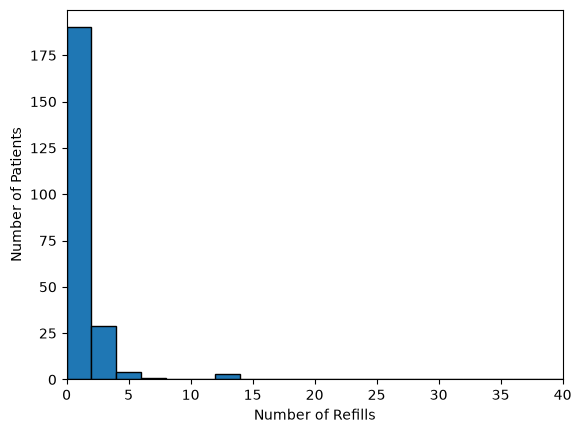

In [49]:
import matplotlib.pyplot as plt
import numpy as np

plt.hist(rx_orders['refills_allowed'].dropna(), bins = np.arange(0,45, 2), edgecolor = "black")
plt.xlim(0,40)
plt.xlabel('Number of Refills')
plt.ylabel("Number of Patients")

plt.savefig("EDA/hist_refills.png", dpi = 300, bbox_inches = "tight")
plt.show()


In [50]:

print(max(rx_orders['refills_allowed']))

123


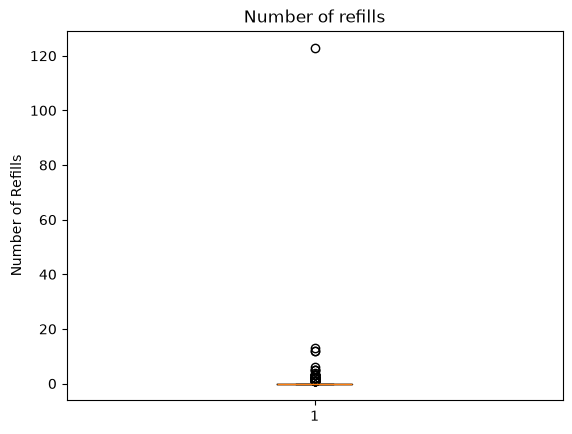

In [59]:
plt.boxplot(rx_orders['refills_allowed'].dropna())
plt.ylabel("Number of Refills")
plt.savefig("EDA/boxplot_refills.png", dpi = 300, bbox_inches = "tight")

plt.title("Number of refills")
plt.show()

In [52]:
rx_orders['quantity'].head()

0    2
1    1
2    3
3    1
4    3
Name: quantity, dtype: int64

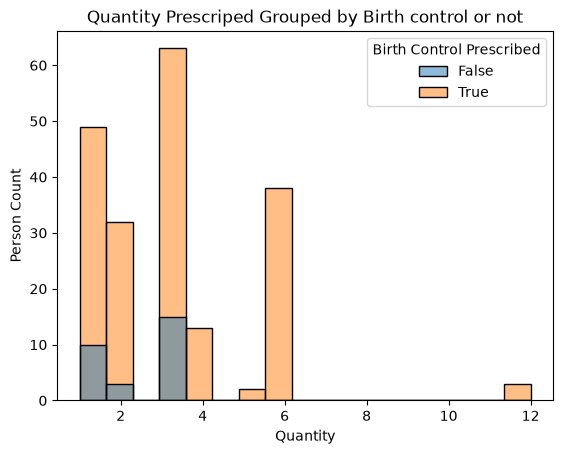

In [60]:
import seaborn as sns
plot=sns.histplot(
    data = rx_orders,
    x="quantity", 
    hue = "bc_prescribed"
)
plot.set(
    xlabel = "Quantity",
    ylabel="Person Count",
    title = "Quantity Prescriped Grouped by Birth control or not"
)

sns.move_legend(
    
    plot, 
    "upper right",
    title = "Birth Control Prescribed"
)
plt.savefig("EDA/quantity_by_bc.png", dpi = 300, bbox_inches = "tight")
plt.show()

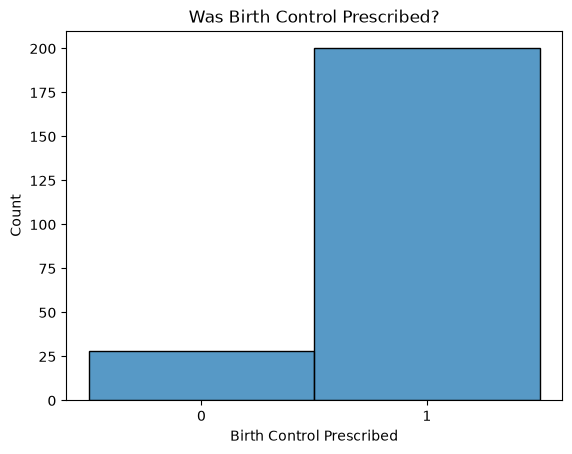

In [54]:

bc=sns.histplot(data = rx_orders, x='bc_prescribed', discrete = True, stat = 'count')
plt.xlabel("Birth Control Prescribed")
plt.title("Was Birth Control Prescribed?")
bc.set_xticks((0,1))
plt.savefig("EDA/bc_prescribed.png", dpi = 300, bbox_inches = "tight")
plt.show()

In [55]:
rx_orders.groupby("bc_prescribed")["quantity"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)


,count,mean,median,std,min,max
bc_prescribed,,,,,,
False,28,2.178571,3.0,0.944911,1,3
True,200,3.140000,3.0,2.042365,1,12


In [56]:
rx_orders['sku'].unique()

<StringArray>
['AD-BC-DAYSEE00', 'AD-BC-FALMIN20', 'AD-BC-ALTAVE00', 'AD-BC-NUVARI00',
 'VC-ASYC-ADCHRG', 'AD-BC-DEPOTP00', 'AD-BC-DROS03LE', 'AD-BC-JUNE20FE',
 'AD-BC-XULANE00', 'AD-BC-EXTERNAL', 'VC-SYNC-15CHRG', 'AD-BC-FREE0000',
 'AD-BC-NEXT3142', 'AD-BC-SLYND000']
Length: 14, dtype: str

In [57]:
rx_orders.groupby("sku")["quantity"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

,count,mean,median,std,min,max
sku,,,,,,
AD-BC-ALTAVE00,22,3.136364,3.0,0.639602,3,6
AD-BC-DAYSEE00,43,2.372093,2.0,0.756661,2,4
AD-BC-DEPOTP00,30,1.200000,1.0,0.610257,1,3
AD-BC-DROS03LE,13,3.846154,3.0,1.344504,3,6
AD-BC-EXTERNAL,4,2.250000,2.0,1.500000,1,4
AD-BC-FALMIN20,31,1.516129,1.0,1.150970,1,5
AD-BC-FREE0000,1,3.000000,3.0,NaN,3,3
AD-BC-JUNE20FE,38,6.105263,6.0,1.997153,3,12
AD-BC-NEXT3142,4,3.000000,3.0,0.000000,3,3


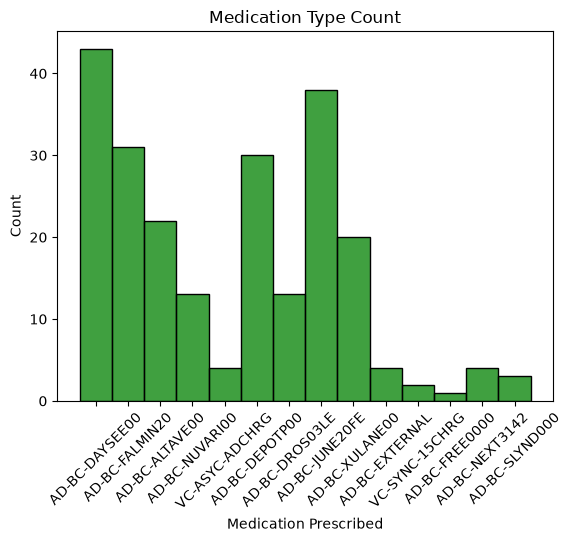

In [58]:
type=sns.histplot(data = rx_orders, x='sku', discrete = True, stat = 'count', color='green')
plt.xlabel("Medication Prescribed")
plt.title("Medication Type Count")
plt.xticks(rotation=45)
#type.set_xticks((0,1))
plt.savefig("EDA/medication_type.png", dpi = 300, bbox_inches = "tight")
plt.show()